In [218]:
%matplotlib inline

import xarray as xr 
import numpy as np
from glob import glob

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import cm
import matplotlib.pyplot as plt

from cmcrameri import cm as cmcra
import plotting_utils
plotting_utils.mk_binary_alpha()

In [ ]:
def get_files(path_source, exp, folders, grid):
    """Array of file paths for the given experiment, folders, and grid."""
    files = sorted(
        f
        for folder in folders
        for f in glob(f"{path_source}{exp}/{folder}/*1y*"+grid+".nc")
    )
    return files


In [3]:
# importing processed dataset
path_source = '../steady_out/' #don't forget the final '/'
exp =  'TEMP'
ds_processed = xr.open_mfdataset(path_source + exp + '.nc')

# warm corresponds to T0=1°C and Fs=0 g/m²/s
ds_warm = ds_processed.sel(T0=1, transition="wtc", Fs=0) 

# cold corresponds to T0=1°C and Fs=0.075 g/m²/s
ds_cold = ds_processed.sel(T0=1, transition="wtc", Fs=0.075)

In [4]:
# Importing raw dataset

path_source = '../raw_yearly_out/' #don't forget the final '/'
exp =  'TEMP1_wtc'


# first importing Warm experiment
years_warm = ["0008", "0009", "0010"]

files = get_files(path_source, exp, years_warm, "T")
dsT_warm = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_warm, "U")
dsU_warm = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_warm, "V")
dsV_warm = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_warm, "W")
dsW_warm = xr.open_mfdataset(
    files,
    combine="by_coords",
)

print(f"Imported warm {exp}")



# then importing Cold experiment
years_cold = ["0158", "0159", "0160"]


files = get_files(path_source, exp, years_cold, "T")
dsT_cold = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_cold, "U")
dsU_cold = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_cold, "V")
dsV_cold = xr.open_mfdataset(
    files,
    combine="by_coords",
)

files = get_files(path_source, exp, years_cold, "W")
dsW_cold = xr.open_mfdataset(
    files,
    combine="by_coords",
)

print(f"Imported cold {exp}")

Imported warm TEMP1_wtc
Imported cold TEMP1_wtc


In [381]:
# Useful functions

def clean_T(ds):
    ds = ds.isel(x=slice(1,127), y=slice(1,27), deptht=slice(0,30))
    return ds

def get_salinity_zonal_mean(ds):
    ds = clean_T(ds)
    sali = ds.vosaline.where(ds.vosaline != 0) #mask over land
    sali = sali.mean(dim='y')
    return sali.values

def get_u_depth_mean_on_T(ds):
    U = ds.vozocrtx.where(ds.vozocrtx != 0) #mask over land
    U = U.mean(dim='depthu')
    U = (U.values[:,:,1:] + U.values[:,:,:-1])/2
    U = U[:,1:,:]
    return U

def get_v_depth_mean_on_T(ds):
    V = ds.vomecrty.where(ds.vomecrty != 0) #mask over land
    V = V.mean(dim='depthv')
    V = (V.values[:,1:,:] + V.values[:,:-1,:])/2
    V = V[:,:,1:]
    return V

def get_moc_on_T(MOC):
    moc = (MOC[:,1:] + MOC[:,:-1])/2
    moc = (moc[:-1,:] + moc[1:,:])/2
    return moc

def get_bsf_on_T(BSF):
    bsf = (BSF[1:] + BSF[:-1])/2
    return bsf


In [55]:
# define grid coordinates

# meridional
x_T = np.arange(1,251+1,2)
x_U = np.arange(0,252+1,2)

# zonal
y_T = np.arange(1,51+1,2)
y_V = np.arange(0,52+1,2)

# depth
z_T = np.arange(10,590+1,20)
z_W = np.arange(0,600+1,20)


# MOC - Salinity plots

In [586]:
def plot_moc_sali(x_T, z_T, sali, moc, plotting_sali, plotting_moc):
    """ Plot the meridional overturning circulation (MOC) overlaid on the salinity field.
    Parameters:
    x_T : array-like
        x-coordinates for the T-grid.
    z_T : array-like
        z-coordinates for the T-grid.
    sali : 2D array
        Salinity field.
    moc : 2D array
        Meridional overturning circulation field.
    plotting_sali : dict
        Dictionary of plotting parameters for salinity.
    plotting_moc : dict
        Dictionary of plotting parameters for MOC.
    """

    fig = plt.figure(figsize=(5.5,1.57), dpi=200)
    ax = plt.gca()

    X_sali, Z_sali = np.meshgrid(x_T, z_T)
    contour_sali = ax.contourf(X_sali, Z_sali, sali, **plotting_sali, )

    X_moc, Z_moc = np.meshgrid(x_T[:-1], z_T)
    contour_moc = ax.contour(X_moc, Z_moc, moc, **plotting_moc)
    ax.clabel(contour_moc, inline=True, use_clabeltext=True, fontsize=6, fmt='%1.2f') #+' Sv')

    ax.plot([100,120], [-0, -0], color='red', linestyle='solid', linewidth=1.5, clip_on=False, zorder=3)

    ax.vlines([240], ymin=0, ymax=600, colors='black', linestyles='dashed', linewidth=1)
    
    ax.set_xlabel('x [km]')
    ax.set_ylabel('Depth [m]')
    
    ax.invert_yaxis()

    ax.set_yticks(np.arange(0,600+1,150))

    ax.set_ylim(600,0)
    ax.set_xlim(0,250)

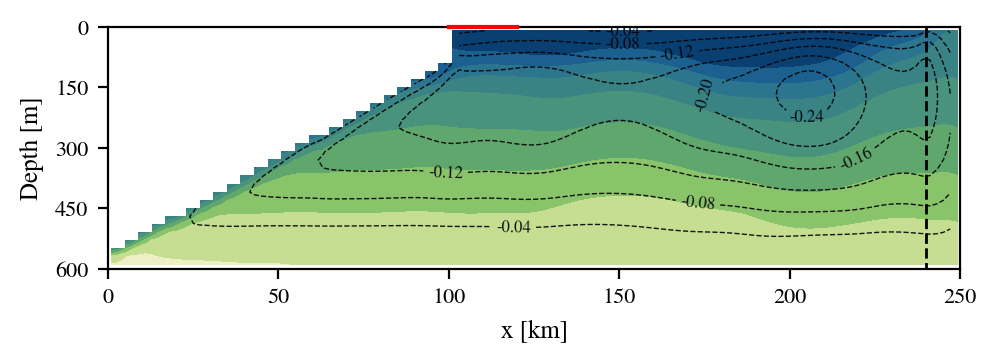

In [587]:
### warm case
ds = ds_warm
dsT = dsT_warm
dsU = dsU_warm
dsV = dsV_warm


# Salinity
sali = get_salinity_zonal_mean(dsT)
sali = np.mean(sali, axis=0)

vmin = 33.6
vmax = 34.6
levels = np.linspace(vmin,vmax,11)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_sali = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.navia , 'levels':levels, 'norm':norm, 'corner_mask':False}

# MOC
moc = ds.MOC.values
moc = get_moc_on_T(moc)

vmin = -0.28
vmax = 0.28
levels = np.linspace(vmin,vmax,15)
color = 'k'
linewidths=0.5
alpha=0.9
plotting_moc = {'vmin':vmin, 'vmax':vmax, 'levels':levels, 'colors':color, 'linewidths':linewidths, 'alpha':alpha}

# Plot the warm case MOC over salinity
plot_moc_sali(x_T, z_T, sali, moc, plotting_sali, plotting_moc)
plt.savefig('./Figure2/salinity_moc.pdf',format='pdf', bbox_inches='tight')
plt.show()


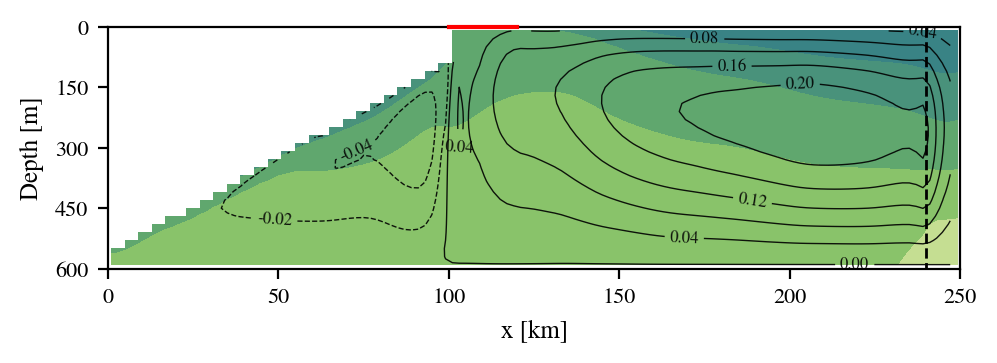

In [588]:
### Cold case
ds = ds_cold
dsT = dsT_cold
dsU = dsU_cold
dsV = dsV_cold


# Salinity
sali = get_salinity_zonal_mean(dsT)
sali = np.mean(sali, axis=0)

vmin = 33.6
vmax = 34.6
levels = np.linspace(vmin,vmax,11)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_sali = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.navia , 'levels':levels, 'norm':norm, 'corner_mask':False}

# MOC
moc = ds.MOC.values
moc = get_moc_on_T(moc)

vmin = -0.28
vmax = 0.28
levels = np.concatenate((np.linspace(vmin,0,15),np.linspace(0.04,vmax,7)))
color = 'k'
linewidths=0.5
alpha=0.9
plotting_moc = {'vmin':vmin, 'vmax':vmax, 'levels':levels, 'colors':color, 'linewidths':linewidths, 'alpha':alpha}

# Plot the cold case MOC over salinity
plot_moc_sali(x_T, z_T, sali, moc, plotting_sali, plotting_moc)
plt.savefig('./Figure3/salinity_moc.pdf',format='pdf', bbox_inches='tight')
plt.show()

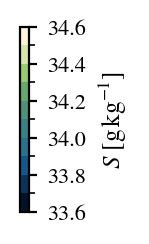

In [589]:
# Generate color bar

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2),dpi=200)  # taller than wide

# Define a generic mappable
levels = np.linspace(33.6,34.6,11)
mappable = matplotlib.cm.ScalarMappable(
    norm=matplotlib.colors.BoundaryNorm(levels, ncolors=256),
    cmap=cmcra.navia
)


cbar = fig_cb.colorbar(
    mappable,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

ax_cb.remove()

cbar.set_label(r'$S$ [$\mathrm{g \, kg^{-1}}$]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig('./Figure2/salinity_bar.pdf',format='pdf', bbox_inches='tight')
plt.savefig('./Figure3/salinity_bar.pdf',format='pdf', bbox_inches='tight')
plt.show()


# Barotropic Stream Function

In [590]:
def plot_bsf_uv(x_T, y_T, bsf, bsf_cav, U, V, plotting_bsf, plotting_bsf_cav, plotting_quiver, quiv_gap, quiv_thresh):
    """
    Plot the basal shear stress (BSF) and depth-averaged velocity (U, V) fields.
    Parameters:
    x_T : array-like
        x-coordinates of the T-grid.
    y_T : array-like
        y-coordinates of the T-grid.
    bsf : array-like
        Barotropic stream function field.
    bsf_cav : array-like
        Barotropic stream function field in the cavity region.
    U : array-like
        Depth-averaged U velocity component.
    V : array-like
        Depth-averaged V velocity component.
    plotting_bsf : dict
        Plotting parameters for the BSF field.
    plotting_bsf_cav : dict
        Plotting parameters for the BSF cavity field.
    plotting_quiver : dict
        Plotting parameters for the quiver plot.
    quiv_gap : int
        Gap between quiver arrows.
    quiv_thresh : float
        Threshold for plotting quiver arrows.
    """

    fig, ax = plt.subplots(figsize=(5.5, 1.1), dpi=200)

    X_bsf, Y_bsf = np.meshgrid(x_T[:-1], y_T[:-1])
    contour_bsf = ax.contourf(X_bsf, Y_bsf, bsf, **plotting_bsf)
    ax.contour(X_bsf, Y_bsf, bsf, levels=[0], colors='white', linewidths=1, zorder=2)

    X_bsf_cav = X_bsf[:,:51]
    Y_bsf_cav = Y_bsf[:,:51]
    cont_bsf_cav = ax.contourf(X_bsf_cav, Y_bsf_cav, bsf_cav, **plotting_bsf_cav)
    ax.contour(X_bsf_cav, Y_bsf_cav, bsf_cav, levels=[0], colors='white', linewidths=1, zorder=2)

    X_uv, Y_uv = np.meshgrid(x_T[:], y_T[:])

    s = quiv_gap
    offset1 = 3
    offset2 = 1
    idx = np.zeros(U.shape, dtype=bool)
    idx[offset1::s, offset1::s] = True
    idx[offset2::s, offset2::s] = True

    ax.quiver(
        X_uv[idx], Y_uv[idx],
        U[idx], V[idx],
        (np.hypot(U, V) >= quiv_thresh)[idx].astype(float),
        **plotting_quiver,
        zorder=2
    )

    ax.set_yticks(ticks=np.arange(0, 51, 25))
    ax.set_ylim(0,50)
    ax.set_xlim(0,250)
    ax.vlines([100, 120], ymin=0, ymax=51, colors='black', linestyles='dotted',linewidths=1)
    ax.vlines([240], ymin=0, ymax=51, colors='black', linestyles='dashed', linewidths=1)
    ax.set_aspect('equal')
    ax.set_xlabel('x [km]')
    ax.set_ylabel('y [km]')
    plt.quiver(50, 2, 0.1, 0, color='red', zorder=2, **plotting_quiver,)
    plt.text(46, 4, r'10 $\mathrm{cm \, s^{-1}}$', color='red', fontsize=6)

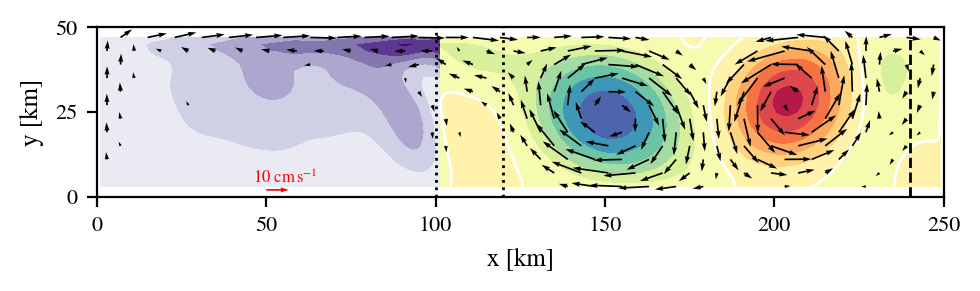

In [591]:
### warm case
ds = ds_warm
dsT = dsT_warm
dsU = dsU_warm
dsV = dsV_warm

# BSF open ocean
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf[:,:50] = np.nan * np.ones((25,50)) # masking cavity

vmin = -1.5
vmax = 1.5
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.Spectral_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# BSF cavity
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf_cav = bsf[:, :51] # taking the cavity part of the BSF

vmin = -0.3
vmax = 0.3
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf_cav = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.PuOr_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# U and V averaged on depth

U = get_u_depth_mean_on_T(dsU)
V = get_v_depth_mean_on_T(dsV)

U = np.mean(U, axis=0)
V = np.mean(V, axis=0)

plotting_quiver = {'scale':0.015, 'cmap':'binary_alpha', 'width':0.5, 'units':'xy', 'pivot':'tail'}
quiv_gap, quiv_thresh = (4,0.02) # (gap, threshold)


plot_bsf_uv(x_T, y_T, bsf, bsf_cav, U, V, plotting_bsf, plotting_bsf_cav, plotting_quiver, quiv_gap, quiv_thresh)
plt.savefig('./Figure2/bsf.pdf',format='pdf', bbox_inches='tight')
plt.show()


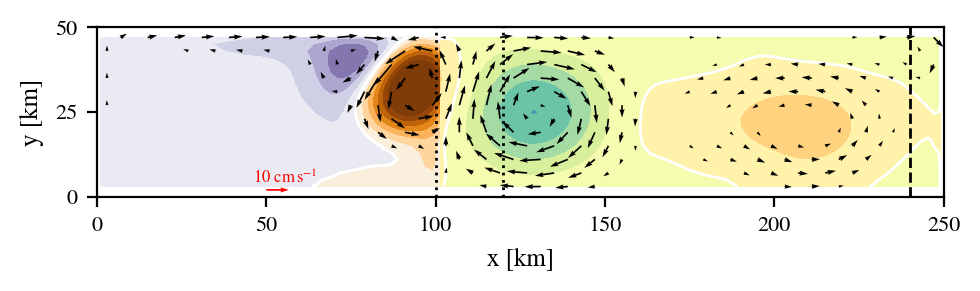

In [592]:
### cold case
ds = ds_cold
dsT = dsT_cold
dsU = dsU_cold
dsV = dsV_cold

# BSF open ocean
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf[:,:50] = np.nan * np.ones((25,50)) # masking cavity

vmin = -1.5
vmax = 1.5
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.Spectral_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# BSF cavity
bsf = ds.BSF.values
bsf = get_bsf_on_T(bsf)
bsf_cav = bsf[:, :51] # taking the cavity part of the BSF

vmin = -0.3
vmax = 0.3
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_bsf_cav = {'vmin':vmin, 'vmax':vmax, 'cmap':cm.PuOr_r, 'levels':levels, 'norm':norm, 'extend':'both'}


# U and V averaged on depth

U = get_u_depth_mean_on_T(dsU)
V = get_v_depth_mean_on_T(dsV)

U = np.mean(U, axis=0)
V = np.mean(V, axis=0)

plotting_quiver = {'scale':0.015, 'cmap':'binary_alpha', 'width':0.5, 'units':'xy', 'pivot':'tail'}
quiv_gap, quiv_thresh = (4,0.02) # (gap, threshold)


plot_bsf_uv(x_T, y_T, bsf, bsf_cav, U, V, plotting_bsf, plotting_bsf_cav, plotting_quiver, quiv_gap, quiv_thresh)
plt.savefig('./Figure3/bsf.pdf',format='pdf', bbox_inches='tight')
plt.show()


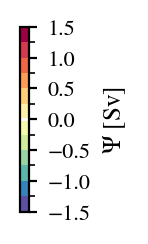

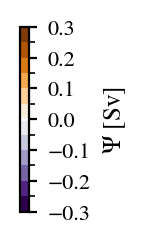

In [594]:
# Generate color bar


# open ocean

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2), dpi=200)  # taller than wide

# Define a generic mappable
levels = np.linspace(-1.5,1.5,13)
mappable = matplotlib.cm.ScalarMappable(
    norm=matplotlib.colors.BoundaryNorm(levels, ncolors=256),
    cmap=cm.Spectral_r
)


cbar = fig_cb.colorbar(
    mappable,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

cbar.ax.axhline(0, color='white', linewidth=1,)

ax_cb.remove()

cbar.set_ticks([-1.5, -1, -0.5, 0, 0.5,1,1.5])

cbar.set_label(r'$\Psi$ [Sv]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig('./Figure2/bsf_bar.pdf',format='pdf', bbox_inches='tight')
plt.savefig('./Figure3/bsf_bar.pdf',format='pdf', bbox_inches='tight')
plt.show()




# Cavity

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 1.2), dpi=200)  # taller than wide

# Define a generic mappable
levels = np.linspace(-0.3,0.3,13)
mappable = matplotlib.cm.ScalarMappable(
    norm=matplotlib.colors.BoundaryNorm(levels, ncolors=256),
    cmap=cm.PuOr_r
)


cbar = fig_cb.colorbar(
    mappable,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

cbar.ax.axhline(0, color='white', linewidth=1,)

ax_cb.remove()

cbar.set_label(r'$\Psi$ [Sv]', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig('./Figure2/bsf_cav_bar.pdf',format='pdf', bbox_inches='tight')
plt.savefig('./Figure3/bsf_cav_bar.pdf',format='pdf', bbox_inches='tight')
plt.show()



# Basal melt rates

In [595]:
def plot_melt(x_T, y_T, melt, utbl, vtbl, plotting_melt, plotting_quiver, quiv_gap):
    """ 
    Plot the melt rate and interface velocity as a quiver plot.
    Parameters
    ----------
    x_T : array-like
        x-coordinates of the grid.
    y_T : array-like
        y-coordinates of the grid.
    melt : 2D array
        Basal melt rate.
    utbl : 2D array
        x-component of the interface velocity.
    vtbl : 2D array
        y-component of the interface velocity.
    plotting_melt : dict
        Plotting parameters for the melt rate.
    plotting_quiver : dict
        Plotting parameters for the quiver plot.
    quiv_gap : int
        Gap between quiver arrows.
    """

    # define axis
    XX, YY = np.meshgrid(x_T[:50],y_T[:-1])

    fig = plt.figure(figsize=(5.5*1/2.5,1.1),dpi=200)
    ax = plt.gca()

    # plot melt
    plot_melt = plt.pcolormesh(XX, YY, melt, **plotting_melt)


    # plot quiver
    s = quiv_gap
    offset1 = 1
    offset2 = 3
    idx = np.zeros(utbl.shape, dtype=bool)
    idx[offset1::s, offset1::s] = True
    idx[offset2::s, offset2::s] = True

    ax.quiver(
        XX[idx], YY[idx],
        utbl[idx], vtbl[idx],
        **plotting_quiver,
        zorder=2
    )


    plt.quiver(62, 2, 0.1, 0, color='red', zorder=2, **plotting_quiver,)
    plt.text(58, 4, r'10 $\mathrm{cm \, s^{-1}}$', color='red', fontsize=6)

    plt.xlim(0,100)
    plt.ylim(0,50)

    plt.xlabel('x [km]')
    plt.ylabel('y [km]')

    ax.set_aspect('equal')

    ax.set_yticks(np.arange(0,51,25))

    cbar = fig.colorbar(
        plot_melt,
        ax=ax,
        fraction=0.15,   # controls width (smaller = thinner)
        aspect=20,       # controls length/thickness ratio
        orientation='vertical'
    )
    cbar.set_label(r'Melt rate [$\mathrm{m \, y^{-1}}$]', fontsize=9)

    cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

    return cbar

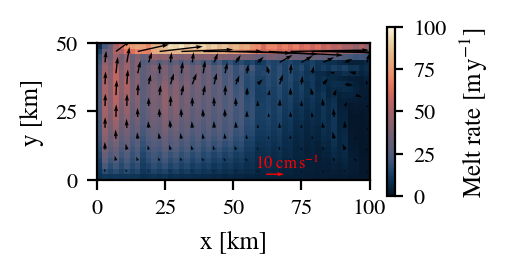

In [596]:
### warm case
ds = ds_warm
dsT = dsT_warm
dsU = dsU_warm
dsV = dsV_warm

# basal melt
melt = ds.melt_2D.isel(x_T=slice(0,50)).values

vmin = 0
vmax = 100
plotting_melt = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.lipari}
#plotting_melt = {'cmap':cmcra.lipari, 'norm':colors.LogNorm(vmin=vmin, vmax=vmax), 'shading':'auto'} # log cmap


# interface velocity
utbl = dsT.utbl.where(dsT.utbl!=0).values
vtbl = dsT.vtbl.where(dsT.vtbl!=0).values

utbl = np.mean(utbl, axis=0)
vtbl = np.mean(vtbl, axis=0)

utbl = utbl[1:-1,1:51]
vtbl = vtbl[1:-1,1:51]

plotting_quiver = {'scale':0.015, 'width':0.5, 'units':'xy', 'pivot':'tail'}
quiv_gap = 4



# plotting
cbar = plot_melt(x_T, y_T, melt, utbl, vtbl, plotting_melt, plotting_quiver, quiv_gap)
cbar.set_ticks([0, 25, 50, 75, 100])
plt.savefig('./Figure2/melt.pdf',format='pdf', bbox_inches='tight')
plt.show()




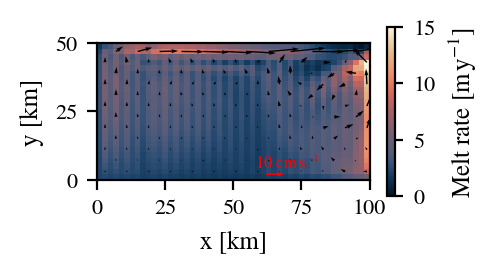

In [597]:
### cold case
ds = ds_cold
dsT = dsT_cold
dsU = dsU_cold
dsV = dsV_cold

# basal melt
melt = ds.melt_2D.isel(x_T=slice(0,50)).values

vmin = 0
vmax = 15
plotting_melt = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.lipari}
#plotting_melt = {'cmap':cmcra.lipari, 'norm':colors.LogNorm(vmin=vmin, vmax=vmax), 'shading':'auto'} # log cmap


# interface velocity
utbl = dsT.utbl.where(dsT.utbl!=0).values
vtbl = dsT.vtbl.where(dsT.vtbl!=0).values

utbl = np.mean(utbl, axis=0)
vtbl = np.mean(vtbl, axis=0)

utbl = utbl[1:-1,1:51]
vtbl = vtbl[1:-1,1:51]

plotting_quiver = {'scale':0.015, 'width':0.5, 'units':'xy', 'pivot':'tail'}
quiv_gap = 4


# plotting
cbar = plot_melt(x_T, y_T, melt, utbl, vtbl, plotting_melt, plotting_quiver, quiv_gap)
cbar.set_ticks([0, 5, 10, 15])
plt.savefig('./Figure3/melt.pdf',format='pdf', bbox_inches='tight')
plt.show()

# Vertical velocity and mixing

In [605]:
def plot_w_evd(x_T, z_W, w_std, evd_frac, plotting_w, plotting_evd):

    # plot vertical velocity standard deviation and EVD activation fraction
    fig = plt.figure(figsize=(8/25*6,1.57), dpi=200)
    ax = plt.gca()

    XX, ZZ = np.meshgrid(x_T, z_W)

    cont_w = ax.contourf(XX, ZZ, w_std*1000, **plotting_w)

    cont_evd = ax.contour(XX, ZZ, evd_frac, **plotting_evd)

    # highlight the ice shelf cavity with a red line
    ax.plot([100,120], [-0, -0], color='red', linestyle='solid', linewidth=1.5, clip_on=False, zorder=3)
            
    ax.set_xlabel('x [km]')
    ax.set_ylabel('Depth [m]')
        
    ax.invert_yaxis()

    ax.set_yticks(np.arange(0,600+1,150))
    ax.set_xticks(np.arange(70,150+1,20))

    ax.set_ylim(600,0)
    ax.set_xlim(70,150)


    # manage cbar
    cbar = fig.colorbar(
        cont_w,
        ax=ax,
        fraction=0.15,   # controls width (smaller = thinner)
        aspect=20       # controls length/thickness ratio
    )

    cbar.set_label(r'$\mathrm{std}(w)$ [$\mathrm{mm\,s^{-1}}$]', fontsize=9)
    cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

    return cbar
    

/tmp/ipykernel_3974/2900564349.py:11: UserWarning: The following kwargs were not used by contour: 'label'
  cont_evd = ax.contour(XX, ZZ, evd_frac, **plotting_evd)


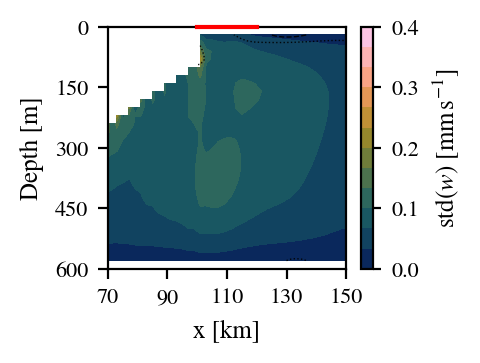

In [610]:
### warm case
ds = ds_warm
dsT = dsT_warm
dsU = dsU_warm
dsV = dsV_warm
dsW = dsW_warm

# standard deviation of vertical velocity
w_std = dsW.vovecrtz_std.where(dsW.vovecrtz_std > 1e-7) #mask over land
w_std = w_std.mean(dim=['y','time_counter']).values
w_std = w_std[:,1:]

vmin = 0
vmax = 0.004/10*1000
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_w = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.batlow , 'levels':levels, 'norm':norm, 'corner_mask':False}


# EVD activation fraction
evd_frac = dsW.evd_diff.where(dsW.vovecrtz_std >= 1e-7)/0.1 # 0.1 is the EVD vertical viscosity
evd_frac = evd_frac.mean(dim=['y','time_counter']).values
evd_frac = evd_frac[:,1:]

levels = [0.1,0.3,0.9]
linestyles = ['dotted','dashed','solid']
plotting_evd = {'levels':levels, 'colors':color, 'linewidths':linewidths, 'alpha':alpha, 'linestyles':linestyles, 'label':'bla'}



# plotting
cbar =plot_w_evd(x_T, z_W, w_std, evd_frac, plotting_w, plotting_evd)
cbar.set_ticks(np.arange(0,0.41,0.1))
plt.savefig('./Figure2/w_evd.pdf',format='pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_3974/2900564349.py:11: UserWarning: The following kwargs were not used by contour: 'label'
  cont_evd = ax.contour(XX, ZZ, evd_frac, **plotting_evd)


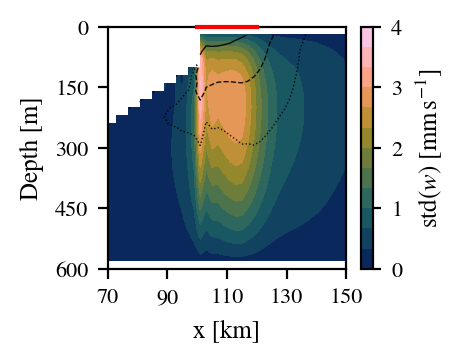

In [611]:
### cold case
ds = ds_cold
dsT = dsT_cold
dsU = dsU_cold
dsV = dsV_cold
dsW = dsW_cold

# standard deviation of vertical velocity
w_std = dsW.vovecrtz_std.where(dsW.vovecrtz_std > 1e-7) #mask over land
w_std = w_std.mean(dim=['y','time_counter']).values
w_std = w_std[:,1:]

vmin = 0
vmax = vmax = 0.004*1000
levels = np.linspace(vmin,vmax,13)
norm = colors.Normalize(vmin=vmin, vmax=vmax,)
plotting_w = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.batlow , 'levels':levels, 'norm':norm, 'corner_mask':False}


# EVD activation fraction
evd_frac = dsW.evd_diff.where(dsW.vovecrtz_std >= 1e-7)/0.1 # 0.1 is the EVD vertical viscosity
evd_frac = evd_frac.mean(dim=['y','time_counter']).values
evd_frac = evd_frac[:,1:]

levels = [0.1,0.3,0.9]
linestyles = ['dotted','dashed','solid']
plotting_evd = {'levels':levels, 'colors':color, 'linewidths':linewidths, 'alpha':alpha, 'linestyles':linestyles, 'label':'bla'}



# plotting
cbar =plot_w_evd(x_T, z_W, w_std, evd_frac, plotting_w, plotting_evd)
cbar.set_ticks(np.arange(0,4.1,1))
plt.savefig('./Figure3/w_evd.pdf',format='pdf', bbox_inches='tight')
plt.show()